In [4]:
import mdtraj as md
import os
import matplotlib.pyplot as plt
import numpy as np

In [5]:
RUNS = "/n/home00/ewang03/scratch/GroEL/runs"
systems = {  # name: (trajectory, full solvated topology -- must have the same atoms as the trajectory)
    "WT":   (f"{RUNS}/2026-11-04_57868420/wt_with_ligands.xtc",   f"{RUNS}/2026-11-04_57868420/wt_nadph_tmp_start.pdb"),
    "M20I": (f"{RUNS}/2026-11-04_57886515/m20i_with_ligands.xtc", f"{RUNS}/2026-11-04_57886515/m20i_nadph_tmp_start.pdb"),
}

rmsf = {}
for name, (xtc, pdb) in systems.items():
    # Load only the protein atoms (drops TMP, NADPH, water and ions; ~20 s per run)
    top = md.load_topology(pdb)
    traj = md.load(xtc, top=top, atom_indices=top.select("protein"))

    # Align every frame on the C-alpha atoms, then RMSF of each C-alpha about its average position
    ca = traj.topology.select("name CA")
    traj.superpose(traj, 0, atom_indices=ca)
    resseq = np.array([traj.topology.atom(i).residue.resSeq for i in ca])
    rmsf[name] = (resseq, md.rmsf(traj, None, atom_indices=ca) * 10)  # nm -> Angstrom

    print(f"{name}: {traj.n_frames} frames, {len(ca)} residues")

WT: 10000 frames, 159 residues
M20I: 10000 frames, 159 residues


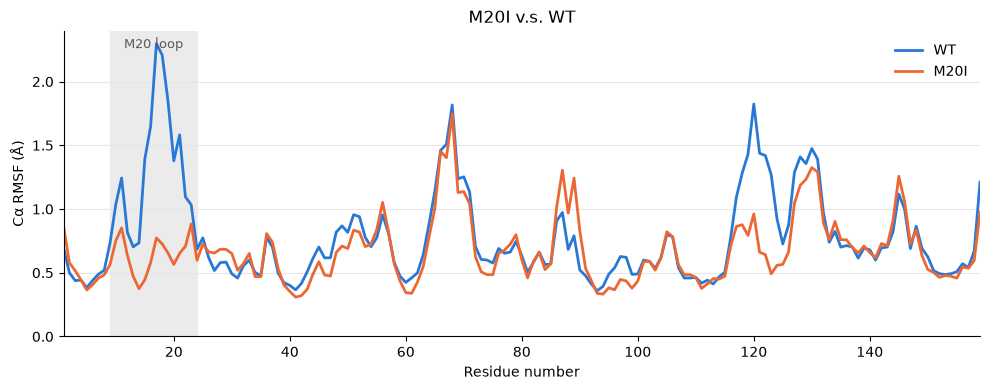

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))

# Shade the Met20 loop (residues 9-24), where the M20I mutation sits
ax.axvspan(9, 24, color="0.92", zorder=0)
ax.text(16.5, 0.98, "M20 loop", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="0.35")

for (name, (resseq, r)), color in zip(rmsf.items(), ["#2a78d6", "#eb6834"]):
    ax.plot(resseq, r, color=color, lw=2, label=name)

ax.set_title("M20I v.s. WT")
ax.set_xlabel("Residue number")
ax.set_ylabel("Cα RMSF (Å)")
ax.set_xlim(1, 159)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()